# RNA ↔ ATAC translation with multiDGD

multiDGD (Schuster *et al.*, *Nat Commun* 2024) is a *deep generative decoder*. It has no encoder:
- each training cell gets its own learnable latent vector;
- a Gaussian mixture is the prior over the latent space;
- one decoder maps a latent to negative-binomial means of every gene **and** every peak, so it models raw counts of both modalities jointly.

A new cell is embedded by optimising a fresh latent with the decoder fixed. For translation, that latent is fitted on the **source modality only** and decoded into the other modality.

This notebook covers:
1. raw-count inputs with `epi.translate.prepare_counts`;
2. training multiDGD and translating held-out cells in both directions;
3. the difference between translation and *joint reconstruction*, which is how the scTranslation benchmark evaluates multiDGD;
4. a benchmark against simple baselines with `epi.translate.benchmark`;
5. how Epione's port compares with the reference implementation.

The [scButterfly notebook](t_translate_scbutterfly.ipynb) introduces the shared interface and metrics.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
import epione as epi

sc.settings.verbosity = 0

## Data and preprocessing

The same 10x Multiome PBMC 10k cells as in the scButterfly notebook, fetched and checksum-verified by `epi.datasets.pbmc10k_multiome`. Set `EPIONE_PBMC10K_DIR` to keep the files outside the pooch cache.

multiDGD models counts, so it needs raw counts, not normalised values. `epi.translate.prepare_counts` does two things:
- **RNA:** selects the 3,000 most variable genes on log-normalised data, as `prepare` does, then returns their **raw counts**;
- **ATAC:** keeps the raw counts of peaks open in at least 0.5% of cells.

In [2]:
rna, atac = epi.datasets.pbmc10k_multiome(os.environ.get("EPIONE_PBMC10K_DIR"))
rna_c, atac_c = epi.translate.prepare_counts(rna, atac)
print(rna_c.shape, atac_c.shape, "integer counts:", float(rna_c.X.max()), float(atac_c.X.max()))

(9631, 3000) (9631, 99272) integer counts: 5585.0 108.0


## Split

The same stratified recipe as the scButterfly notebook: 20% of cells for testing, 10% of the rest for early stopping. It reproduces fold 0 of the parity runs.

In [3]:
from sklearn.model_selection import StratifiedKFold, train_test_split

y = rna_c.obs["cell_type"].astype(str).to_numpy()
rest, test = next(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(y, y))
train, valid = train_test_split(rest, test_size=0.1, stratify=y[rest], random_state=0)
print(f"train {len(train)}, validation {len(valid)}, test {len(test)}")

train 6933, validation 771, test 1927


## Train multiDGD

Each epoch:
- updates the decoder and the mixture after every batch of 128 cells;
- updates the training latents once, from gradients accumulated over the whole epoch.

Validation cells get their own latents, which take one step per epoch. Training stops when the validation reconstruction loss is worse than every value in the last 10 epochs, after at least 50 epochs. There is no rollback to the best epoch.

The defaults are multiDGD's own, except for one: the scTranslation runner gives multiDGD no cell labels, so the mixture has a single component, `n_components=1`. With labels, upstream sets one component per cell type.

In [4]:
t0 = time.time()
model = epi.translate.fit(rna_c, atac_c, method="multidgd", train_idx=train, val_idx=valid, seed=0)
print(model, f"trained in {time.time() - t0:.0f} s, {model.history['epochs']} epochs")

<MultiDGD multidgd: 3000 genes <-> 99272 peaks> trained in 991 s, 491 epochs


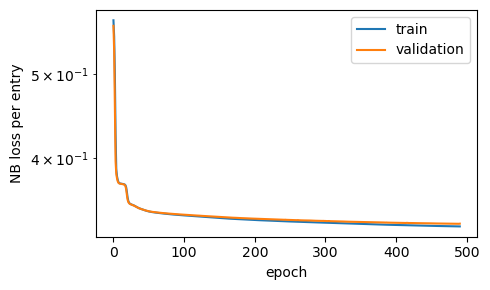

In [5]:
h = model.history
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(h["reconstruction"], label="train")
ax.plot(h["val_reconstruction"], label="validation")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("NB loss per entry")
ax.legend()
fig.tight_layout()

## Translate held-out cells

`model.predict` fits a latent for each test cell from its source modality alone, then decodes the target modality. multiDGD's output is a per-cell *fraction* over the target features: each row sums to 1. Multiply by a library size to get expected counts.

To compare predictions with measurements, the helper below puts both on one scale: counts per 10,000, then `log1p`.

In [6]:
atac_pred = model.predict(rna_c[test])    # RNA -> ATAC
rna_pred = model.predict(atac_c[test])    # ATAC -> RNA
print(atac_pred.shape, rna_pred.shape, "rows sum to", float(atac_pred.X[:3].sum(1).mean()))

def logcp10k(ad):
    X = ad.X.toarray() if sp.issparse(ad.X) else np.asarray(ad.X, dtype=np.float64)
    X = np.log1p(X / X.sum(1, keepdims=True) * 1e4).astype(np.float32)
    return sc.AnnData(X, obs=ad.obs[["cell_type"]].copy(), var=pd.DataFrame(index=ad.var_names))

truth = {"rna2atac": logcp10k(atac_c[test]), "atac2rna": logcp10k(rna_c[test])}

(1927, 99272) (1927, 3000) rows sum to 1.0


## Translation vs joint reconstruction

The scTranslation benchmark evaluates multiDGD differently. It fits the test latents on the concatenated RNA **and** ATAC of each test cell, then reads the "translated" modality off the decoder. The target modality is part of the input, so that is joint reconstruction, not translation.

`model.reconstruct` reproduces that protocol. Comparing the two shows how much of a joint-reconstruction score comes from seeing the answer.

In [7]:
rna_joint, atac_joint = model.reconstruct(rna_c[test], atac_c[test])

def per_cell_pcc(pred, tru):
    p, t = pred.X, tru.X
    p = (p - p.mean(1, keepdims=True)) / p.std(1, keepdims=True)
    t = (t - t.mean(1, keepdims=True)) / t.std(1, keepdims=True)
    return (p * t).mean(1)

rows = []
for task, src, joint in [("rna2atac", atac_pred, atac_joint), ("atac2rna", rna_pred, rna_joint)]:
    rows.append({"task": task,
                 "translation (source only)": np.median(per_cell_pcc(logcp10k(src), truth[task])),
                 "joint reconstruction": np.median(per_cell_pcc(logcp10k(joint), truth[task]))})
pd.DataFrame(rows).set_index("task").round(3)

,translation (source only),joint reconstruction
task,,
rna2atac,0.518,0.530
atac2rna,0.346,0.349


The UMAPs below come from measured accessibility and from accessibility translated from RNA. Colours are shared across panels.

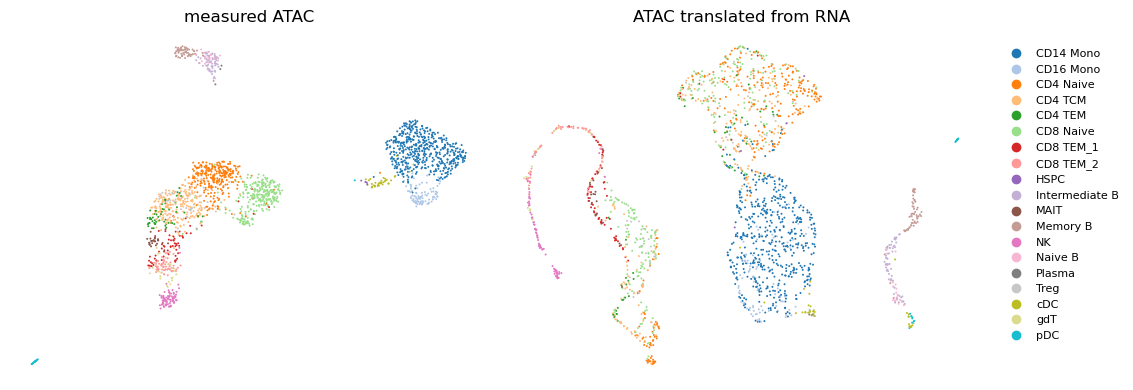

In [8]:
types = sorted(rna_c.obs["cell_type"].astype(str).unique())
palette = dict(zip(types, plt.get_cmap("tab20").colors + plt.get_cmap("tab20b").colors))

def umap_of(ad, title, ax):
    a = ad.copy()
    a.obs["cell_type"] = pd.Categorical(a.obs["cell_type"].astype(str), categories=types)
    sc.pp.pca(a, n_comps=50)
    sc.pp.neighbors(a)
    sc.tl.umap(a, random_state=0)
    sc.pl.umap(a, color="cell_type", palette=palette, ax=ax, show=False, title=title,
               legend_loc=None, frameon=False, s=8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
umap_of(truth["rna2atac"], "measured ATAC", axes[0])
umap_of(logcp10k(atac_pred), "ATAC translated from RNA", axes[1])
handles = [plt.Line2D([], [], marker="o", ls="", color=palette[t], label=t) for t in types]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8)
fig.tight_layout()

## Benchmark

The same scib-style benchmark as in the scButterfly notebook, here with four entries:
- multiDGD's translation;
- multiDGD's joint reconstruction, for reference only (it saw the target modality);
- two baselines, kNN (mean target profile of the 10 nearest training cells in the source modality, 50 SVD components) and the mean training profile.

Everything is scored on log1p(CP10k).

In [9]:
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors

def knn_translate(src, dst, k=10):
    s = logcp10k(src).X
    svd = TruncatedSVD(50, random_state=0).fit(s[train])
    nn = NearestNeighbors(n_neighbors=k).fit(svd.transform(s[train]))
    idx = nn.kneighbors(svd.transform(s[test]), return_distance=False)
    Y = sp.csr_matrix(dst.X)
    pred = np.vstack([np.asarray(Y[train[i]].sum(axis=0)).ravel() for i in idx]).astype(np.float32)
    return sc.AnnData(pred, obs=dst.obs.iloc[test].copy(), var=pd.DataFrame(index=dst.var_names))

def mean_translate(dst):
    m = np.asarray(sp.csr_matrix(dst.X)[train].sum(axis=0)).astype(np.float32)
    return sc.AnnData(np.repeat(m, len(test), axis=0), obs=dst.obs.iloc[test].copy(),
                      var=pd.DataFrame(index=dst.var_names))

preds = {
    "rna2atac": {"multiDGD": atac_pred, "multiDGD (joint, not translation)": atac_joint,
                 "kNN": knn_translate(rna_c, atac_c), "mean": mean_translate(atac_c)},
    "atac2rna": {"multiDGD": rna_pred, "multiDGD (joint, not translation)": rna_joint,
                 "kNN": knn_translate(atac_c, rna_c), "mean": mean_translate(rna_c)},
}
preds = {t: {m: logcp10k(p) for m, p in d.items()} for t, d in preds.items()}
res = epi.translate.benchmark(preds, truth, labels="cell_type")
epi.translate.summarize(res).round(3)

metric                              \
                                              ARI    AMI    NMI    HOM    PCC   
task     method                                                                 
atac2rna kNN                                0.448  0.713  0.723  0.802  0.556   
         mean                               0.002 -0.003  0.052  0.057  0.461   
         multiDGD (joint, not translation)  0.170  0.455  0.477  0.540  0.359   
         multiDGD                           0.181  0.465  0.486  0.544  0.357   
rna2atac mean                               0.002  0.000  0.056  0.065  0.531   
         kNN                                0.472  0.744  0.754  0.836  0.513   
         multiDGD (joint, not translation)  0.217  0.485  0.503  0.559  0.508   
         multiDGD                           0.179  0.481  0.502  0.577  0.497   

                                                                               \
                                             SPCC   CORR    MSE    MAE    MMD   
task     method                                                                 
atac2rna kNN                                0.393  0.172  0.655  0.369  0.948   
         mean                               0.312    NaN  0.881  0.599  4.343   
         multiDGD (joint, not translation)  0.285  0.075  1.533  0.972  5.310   
         multiDGD                           0.284  0.081  1.537  0.974  5.364   
rna2atac mean                               0.331    NaN  0.039  0.093  2.888   
         kNN                                0.381  0.086  0.042  0.086  0.662   
         multiDGD (joint, not translation)  0.318  0.081  0.039  0.106  2.961   
         multiDGD                           0.319  0.061  0.040  0.107  2.096   

                                                                     score  \
                                            iLISI  AUROC  AUPRC clustering   
task     method                                                              
atac2rna kNN                                0.000  0.858  0.502      1.000   
         mean                               0.000  0.870  0.360      0.000   
         multiDGD (joint, not translation)  0.000  0.838  0.296      0.574   
         multiDGD                           0.000  0.836  0.292      0.588   
rna2atac mean                               0.258  0.863  0.431      0.000   
         kNN                                0.000  0.838  0.404      1.000   
         multiDGD (joint, not translation)  0.000  0.851  0.424      0.598   
         multiDGD                           0.000  0.854  0.406      0.582   

                                                                    \
                                           regression distribution   
task     method                                                      
atac2rna kNN                                    1.000        0.538   
         mean                                   0.537        0.616   
         multiDGD (joint, not translation)      0.007        0.006   
         multiDGD                               0.012        0.000   
rna2atac mean                                   0.721        0.516   
         kNN                                    0.691        0.500   
         multiDGD (joint, not translation)      0.411        0.000   
         multiDGD                               0.127        0.188   

                                                                   
                                           classification overall  
task     method                                                    
atac2rna kNN                                        0.825   0.841  
         mean                                       0.662   0.454  
         multiDGD (joint, not translation)          0.032   0.155  
         multiDGD                                   0.000   0.150  
rna2atac mean                                       1.000   0.559  
         kNN                                        0.000   0.548  
         multiDGD

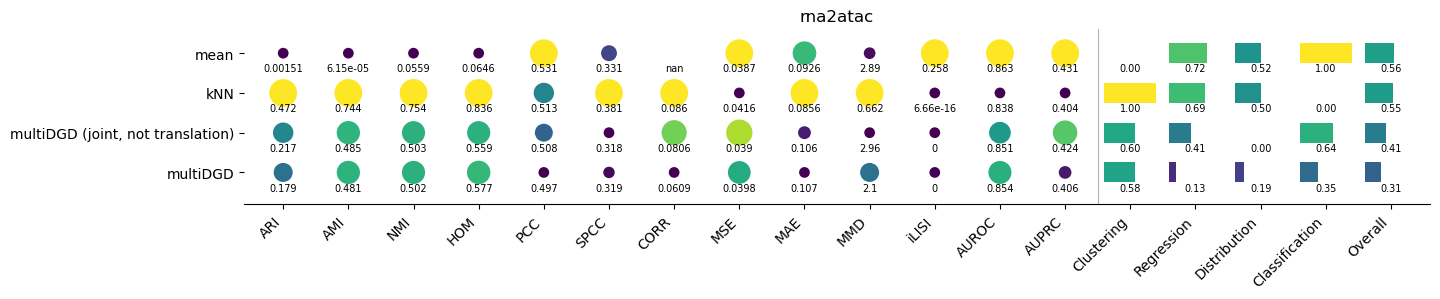

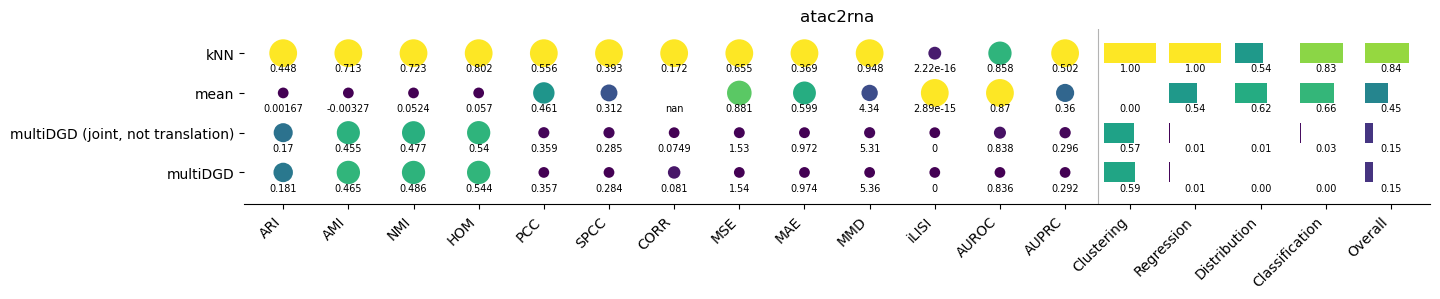

In [10]:
for task in ["rna2atac", "atac2rna"]:
    epi.translate.plot_benchmark(res, task=task)

In each plot, a row is a method and a column a metric:
- **dots:** the raw value is printed underneath; size and colour show the value min-max scaled across methods for that metric, with lower-is-better metrics (MSE, MAE, MMD) flipped so that bigger is always better;
- **bars:** the scaled scores averaged within each category (clustering, regression, distribution, classification) and overall.

The joint-reconstruction row is not a translator: it is there to show what seeing the target modality is worth.

**What this shows, at the benchmark's settings.** These are one mixture component (the scTranslation runner passes no cell labels) and 20 optimisation steps per new cell. Under them:
- multiDGD ranks below the kNN baseline on clustering and on per-cell correlation;
- on per-cell PCC it is also below the mean training profile;
- joint reconstruction is barely better than translation, because seeing the target modality adds little.

We report these numbers as measured, without tuning. Two settings would be natural to try: `n_components` set to the number of cell types, which is what upstream does when labels are given, and more `inference_epochs`.

## Save and load

In [11]:
import tempfile

path = os.path.join(tempfile.mkdtemp(), "multidgd.pt")
model.save(path)
again = epi.translate.load(path)
np.allclose(again.predict(rna_c[test[:50]]).X, model.predict(rna_c[test[:50]]).X, atol=1e-5)

True

## Validation against the reference implementation

Epione's port was checked against scTranslation's multiDGD runs on fold 0, with 3 seeds on each side. The tolerances were registered before any Epione run; the full record is `tests/parity/translate_multidgd/MANIFEST.md`.

| gate | result |
|---|---|
| preprocessing (`prepare_counts` vs reference inputs) | identical |
| metrics recomputed on the reference predictions | identical to ≤ 2e-6, except one Leiden ARI |
| training parity (joint inference, unshuffled, as the reference ran) | **22 of 23 gated metrics pass**. ATAC→RNA per-cell PCC is 0.907 vs 0.927, just outside the tolerance (\|Δ\| 0.0200 vs 0.0195) |
| `fast=True` vs default | all 23 within tolerance; median 2.1× faster |

Two properties of the benchmark's protocol matter for reading its multiDGD numbers:
1. It fits test latents on **both** modalities.
2. It scores multiDGD's per-cell fractions against raw counts, so MSE, MAE, MMD and LISI reflect the scale mismatch rather than the model.

That is why this notebook scores everything on log1p(CP10k).